In [64]:
import pandas as pd

In [65]:
from pathlib import Path
import pandas as pd

file_path = Path(
    r"C:\test\01_원본데이터\서울시 소유 전기차충전기 일별 시간별 충전현황(2025년).xlsx"
)

print("파일 존재 여부:", file_path.exists())

파일 존재 여부: True


In [66]:
# 각 열의 고유값 개수 확인 충전소별 데이터 개수 확인  
for col in df.columns:
    print(f"{col}: {df[col].nunique()}개")

충전소명: 213개
충전시작시간: 214539개
충전종료시간: 214380개
충전량(kW): 29969개
충전시간_분: 17893개


In [67]:
# 충전소별 데이터 개수
print(df["충전소명"].value_counts())

충전소명
양재솔라스테이션                  6283
청계5 노상공영주차장(가로등)          5279
강남구 압구정 나들목 앞 가로등형 충전기    4787
청계8가 노상공영주차장(가로등)         4565
동대문구청                     4430
                          ... 
신월5동 주민센터                    1
목2동 주민센터                     1
곰달래 공영주차장                    1
상계2동 공영주차장                   1
시흥4동 공영주차장                   1
Name: count, Length: 213, dtype: int64


In [68]:
# 중복을 제외한 충전소명 목록
print(df["충전소명"].unique())

# 충전소 개수
print("충전소 개수:", df["충전소명"].nunique())

<ArrowStringArray>
[   '기업은행 무교지점 앞 가로등형 충전소',       '이문동 거주자우선주차장(가로등)',
             '아현2구역 공영주차장',                 'AI 체육센터',
                    '중랑구청',      '위례성길 공영주차장 전기차 충전소',
 '잠실 청소년센터 앞 전기차 충전소(가로등)',                '서울숲공원주차장',
                 '노원수학문화관',         '월계동 거주자주차장(가로등)',
 ...
               '대청역 공영주차장',                  '구로문화누리',
        '마장축산물시장 서문 공영주차장',                  '문화비축기지',
             '해누리타운 지하주차장',              '상계2동 공영주차장',
              '시흥4동 공영주차장',               '적선동 공영주차장',
     '문정1동 주민센터 앞 전기차 충전소', '국립한글박물관 지하주차장(주차장 임시폐쇄)']
Length: 213, dtype: str
충전소 개수: 213


In [69]:
# 충전소명별로 데이터 그룹화
groups = df.groupby("충전소명")

# 충전소 개수 확인
print("충전소 개수:", df["충전소명"].nunique())

충전소 개수: 213


In [70]:
# 첫 번째 충전소 이름 확인
name = df["충전소명"].unique()[0]
print(name)

# 해당 충전소 데이터만 보기
display(df[df["충전소명"] == name])

기업은행 무교지점 앞 가로등형 충전소


,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
0,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 23:59:47,2026-01-01 00:21:26,15.51,21.650000
64,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 21:45:57,2025-12-31 22:32:11,33.34,46.233333
108,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 20:40:52,2025-12-31 21:18:28,22.53,37.600000
472,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 13:49:26,2025-12-31 15:50:44,25.95,121.300000
676,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 09:52:47,2025-12-31 10:37:24,10.59,44.616667
...,...,...,...,...,...
214994,기업은행 무교지점 앞 가로등형 충전소,2025-01-02 11:02:41,2025-01-02 12:16:44,24.20,74.050000
215190,기업은행 무교지점 앞 가로등형 충전소,2025-01-01 21:39:46,2025-01-01 22:19:36,13.68,39.833333
215225,기업은행 무교지점 앞 가로등형 충전소,2025-01-01 19:15:49,2025-01-01 20:01:47,33.09,45.966667
215272,기업은행 무교지점 앞 가로등형 충전소,2025-01-01 16:58:36,2025-01-01 17:41:29,30.89,42.883333


In [71]:
import pandas as pd

# 시작 시간과 종료 시간을 날짜/시간 형식으로 변환
df["충전시작시간"] = pd.to_datetime(df["충전시작시간"])
df["충전종료시간"] = pd.to_datetime(df["충전종료시간"])

# 종료 시간 - 시작 시간 → 분 단위로 변환
df["충전시간_분"] = (
    df["충전종료시간"] - df["충전시작시간"]
).dt.total_seconds() / 60

# 결과 확인
display(df.head())

,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
0,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 23:59:47,2026-01-01 00:21:26,15.51,21.65
1,이문동 거주자우선주차장(가로등),2025-12-31 23:55:36,2026-01-01 00:26:45,8.84,31.15
2,아현2구역 공영주차장,2025-12-31 23:52:04,2026-01-01 00:03:43,4.06,11.65
3,AI 체육센터,2025-12-31 23:47:48,2026-01-01 00:19:03,22.27,31.25
4,중랑구청,2025-12-31 23:42:36,2026-01-01 00:05:27,15.28,22.85


In [72]:
# 행과 열 개수 확인
print(df.shape)

(215532, 5)


In [73]:
print(df.columns.tolist())

['충전소명', '충전시작시간', '충전종료시간', '충전량(kW)', '충전시간_분']


In [74]:
# 충전량을 숫자형으로 변환
df["충전량(kW)"] = pd.to_numeric(
    df["충전량(kW)"], errors="coerce"
)

# 최솟값과 최댓값 확인
print("충전량 최솟값:", df["충전량(kW)"].min())
print("충전량 최댓값:", df["충전량(kW)"].max())

충전량 최솟값: -35707.73
충전량 최댓값: 46702.02


In [75]:
# 충전량이 0보다 작은 데이터
negative_df = df[df["충전량(kW)"] < 0]

print("음수 데이터 개수:", len(negative_df))
display(negative_df.head(10))

음수 데이터 개수: 1


,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
70313,"중곡동 복개천 노상공영주차장(중곡동우체국 앞, 가로등)",2025-09-23 21:31:20,2025-09-23 21:54:01,-35707.73,22.683333


In [76]:
# 충전량이 절댓값 기준으로 100보다 큰 데이터 확인
display(
    df[df["충전량(kW)"].abs() > 100]
    .sort_values("충전량(kW)")
)

,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
70313,"중곡동 복개천 노상공영주차장(중곡동우체국 앞, 가로등)",2025-09-23 21:31:20,2025-09-23 21:54:01,-35707.73,22.683333
51418,강남구 압구정 나들목 앞 가로등형 충전기,2025-10-26 10:46:14,2025-10-26 13:23:42,100.01,157.466667
81474,면일초등학교 공영주차장,2025-09-05 23:21:04,2025-09-06 01:44:46,100.54,143.700000
98458,잠실 청소년센터 앞 전기차 충전소(가로등),2025-08-09 21:46:00,2025-08-10 00:21:21,102.53,155.350000
135121,강남구 압구정 나들목 앞 가로등형 충전기,2025-06-09 11:54:23,2025-06-09 14:46:28,106.57,172.083333
21643,논현2동 주민센터,2025-12-05 18:53:24,2025-12-06 12:15:14,114.61,1041.833333
61109,월계복지문화센터,2025-10-10 18:21:31,2025-10-10 18:48:34,46702.02,27.050000


In [77]:
# 음수 충전량 제외한 분석용 데이터
df_clean = df[df["충전량(kW)"] >= 0].copy()

print("원본 데이터:", len(df))
print("분석용 데이터:", len(df_clean))
print("제외한 데이터:", len(df) - len(df_clean))

원본 데이터: 215532
분석용 데이터: 215531
제외한 데이터: 1


In [78]:
# 분석용 데이터의 충전량 분포 확인
print(df_clean["충전량(kW)"].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
))

# 충전량이 큰 데이터 확인
display(
    df_clean.nlargest(10, "충전량(kW)")[
        ["충전소명", "충전시작시간", "충전종료시간",
         "충전량(kW)", "충전시간_분"]
    ]
)

count    215531.000000
mean         21.755255
std         101.649428
min           0.000000
1%            0.000000
5%            0.305000
50%          19.790000
95%          48.150000
99%          60.590000
max       46702.020000
Name: 충전량(kW), dtype: float64


,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
61109,월계복지문화센터,2025-10-10 18:21:31,2025-10-10 18:48:34,46702.02,27.050000
21643,논현2동 주민센터,2025-12-05 18:53:24,2025-12-06 12:15:14,114.61,1041.833333
135121,강남구 압구정 나들목 앞 가로등형 충전기,2025-06-09 11:54:23,2025-06-09 14:46:28,106.57,172.083333
98458,잠실 청소년센터 앞 전기차 충전소(가로등),2025-08-09 21:46:00,2025-08-10 00:21:21,102.53,155.350000
81474,면일초등학교 공영주차장,2025-09-05 23:21:04,2025-09-06 01:44:46,100.54,143.700000
51418,강남구 압구정 나들목 앞 가로등형 충전기,2025-10-26 10:46:14,2025-10-26 13:23:42,100.01,157.466667
153875,잠실 청소년센터 앞 전기차 충전소(가로등),2025-05-02 03:27:39,2025-05-02 06:01:26,100.00,153.783333
17205,교통공원길 공영주차장 전기차 충전소,2025-12-11 10:26:35,2025-12-11 12:52:22,99.57,145.783333
152417,창2동 제4공영주차장,2025-05-05 13:50:58,2025-05-05 16:03:03,97.12,132.083333
78525,기업은행 무교지점 앞 가로등형 충전소,2025-09-10 23:04:50,2025-09-11 01:27:27,96.94,142.616667


In [79]:
display(
    df_clean[df_clean["충전량(kW)"] > 1000][
        ["충전소명", "충전시작시간", "충전종료시간",
         "충전량(kW)", "충전시간_분"]
    ].sort_values("충전량(kW)", ascending=False)
)

,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
61109,월계복지문화센터,2025-10-10 18:21:31,2025-10-10 18:48:34,46702.02,27.05


In [80]:
# 원본 데이터에서 음수와 극단값만 제외
df_model = df[
    (df["충전량(kW)"] >= 0) &
    (df["충전량(kW)"] <= 1000)
].copy()

print("원본 데이터:", len(df))
print("분석용 데이터:", len(df_model))
print("제외한 데이터:", len(df) - len(df_model))

원본 데이터: 215532
분석용 데이터: 215530
제외한 데이터: 2


In [81]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, data in df_model.groupby("충전소명"):

    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    # 데이터가 2개 미만이면 건너뛰기
    if len(data) < 10:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "충전소명": name,
        "데이터 개수": len(data),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

if not results_df.empty:
    results_df = results_df.sort_values("R2", ascending=False)
    display(results_df)

print("모델을 실행한 충전소 수:", len(results_df))

,충전소명,데이터 개수,MAE,RMSE,R2
86,사당종합체육관,200,0.421422,0.543663,0.992709
69,미아동 도봉세무서 앞 전기차 충전소,518,1.162947,1.878473,0.991163
78,봉화산역 공영주차장 전기차 충전소,756,1.571633,2.141916,0.986712
142,으뜸공원 공영주차장 전기차 충전소,439,1.456386,2.096946,0.984108
51,로봇과학관,87,0.941812,1.518333,0.981174
...,...,...,...,...,...
22,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.016124,30.178582,-2.463987
55,마포유수지 공영주차장,1235,10.533730,29.523735,-2.468554
181,한마음공영주차장,933,11.105968,32.218113,-2.662466
26,남산청사,1203,2.642390,14.273589,-7.110992


모델을 실행한 충전소 수: 191


In [82]:
# R² 기준으로 충전소 성능 분류
def classify_r2(r2):
    if r2 < 0:
        return "성능 낮음 (R² < 0)"
    elif r2 < 0.5:
        return "설명력 낮음 (0 ≤ R² < 0.5)"
    else:
        return "설명력 상대적으로 높음 (R² ≥ 0.5)"

results_df["성능 분류"] = results_df["R2"].apply(classify_r2)

# 분류별 충전소 개수
print(results_df["성능 분류"].value_counts())

# 분류별 충전소 목록 확인
display(
    results_df.sort_values(["성능 분류", "R2"])[
        ["충전소명", "데이터 개수", "MAE", "RMSE", "R2", "성능 분류"]
    ]
)

성능 분류
설명력 상대적으로 높음 (R² ≥ 0.5)    132
설명력 낮음 (0 ≤ R² < 0.5)       46
성능 낮음 (R² < 0)              13
Name: count, dtype: int64


,충전소명,데이터 개수,MAE,RMSE,R2,성능 분류
3,가산 공영주차장,420,6.821968,8.304689,0.009091,설명력 낮음 (0 ≤ R² < 0.5)
63,목동공영주차장,3260,12.877826,15.574540,0.046303,설명력 낮음 (0 ≤ R² < 0.5)
48,동작구청,2826,4.701819,5.738728,0.051574,설명력 낮음 (0 ≤ R² < 0.5)
105,송월동차고지,2935,12.166415,15.081155,0.064478,설명력 낮음 (0 ≤ R² < 0.5)
112,수서역 공영주차장 복합충전소,3924,11.361253,14.099602,0.075388,설명력 낮음 (0 ≤ R² < 0.5)
...,...,...,...,...,...,...
128,어린이대공원 구의문 주차장 복합충전소,4065,11.816192,15.872260,-0.092692,성능 낮음 (R² < 0)
18,교통공원길 공영주차장 전기차 충전소,1520,13.005449,19.245865,-0.021102,성능 낮음 (R² < 0)
0,50+동부캠퍼스,490,13.489312,15.652546,-0.005852,성능 낮음 (R² < 0)
140,월계복지문화센터,208,12.629780,16.116989,-0.004401,성능 낮음 (R² < 0)


In [83]:
# R²가 음수인 충전소 13개 확인
low_r2 = results_df[results_df["R2"] < 0].sort_values("R2")

display(low_r2[
    ["충전소명", "데이터 개수", "MAE", "RMSE", "R2"]
])

,충전소명,데이터 개수,MAE,RMSE,R2
124,앵봉산가족캠핑장,102,25.737570,95.692724,-32.804171
26,남산청사,1203,2.642390,14.273589,-7.110992
181,한마음공영주차장,933,11.105968,32.218113,-2.662466
55,마포유수지 공영주차장,1235,10.533730,29.523735,-2.468554
22,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.016124,30.178582,-2.463987
131,여의서로 노상공영주차장(가로등),1663,5.948548,21.672615,-1.903109
81,불암산공영주차장,196,10.761056,20.613299,-1.267559
28,노원구청,1046,10.413723,16.867754,-0.386079
128,어린이대공원 구의문 주차장 복합충전소,4065,11.816192,15.872260,-0.092692
18,교통공원길 공영주차장 전기차 충전소,1520,13.005449,19.245865,-0.021102


In [84]:
# R²가 가장 낮은 충전소 확인
display(
    results_df[results_df["R2"] < 0]
    .sort_values("R2")
    .head(13)
)

,충전소명,데이터 개수,MAE,RMSE,R2,성능 분류
124,앵봉산가족캠핑장,102,25.737570,95.692724,-32.804171,성능 낮음 (R² < 0)
26,남산청사,1203,2.642390,14.273589,-7.110992,성능 낮음 (R² < 0)
181,한마음공영주차장,933,11.105968,32.218113,-2.662466,성능 낮음 (R² < 0)
55,마포유수지 공영주차장,1235,10.533730,29.523735,-2.468554,성능 낮음 (R² < 0)
22,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.016124,30.178582,-2.463987,성능 낮음 (R² < 0)
131,여의서로 노상공영주차장(가로등),1663,5.948548,21.672615,-1.903109,성능 낮음 (R² < 0)
81,불암산공영주차장,196,10.761056,20.613299,-1.267559,성능 낮음 (R² < 0)
28,노원구청,1046,10.413723,16.867754,-0.386079,성능 낮음 (R² < 0)
128,어린이대공원 구의문 주차장 복합충전소,4065,11.816192,15.872260,-0.092692,성능 낮음 (R² < 0)
18,교통공원길 공영주차장 전기차 충전소,1520,13.005449,19.245865,-0.021102,성능 낮음 (R² < 0)


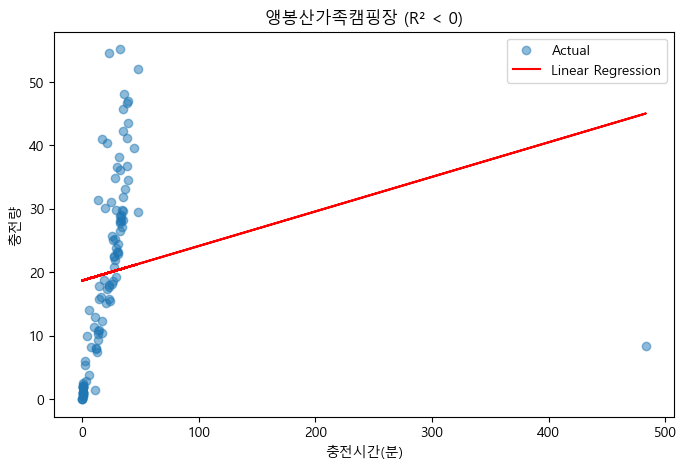

선택한 충전소: 앵봉산가족캠핑장


In [85]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# R²가 가장 낮은 충전소 선택
name = results_df[results_df["R2"] < 0].sort_values("R2").iloc[0]["충전소명"]

data = df_model[df_model["충전소명"] == name][
    ["충전시간_분", "충전량(kW)"]
].dropna().copy()

# 해당 충전소의 선형회귀 직선 계산
X = data[["충전시간_분"]]
y = data["충전량(kW)"]

model_check = LinearRegression()
model_check.fit(X, y)

data["예측값"] = model_check.predict(X)
data["절대오차"] = (data["충전량(kW)"] - data["예측값"]).abs()

# 실제 데이터와 직선 표시
plt.figure(figsize=(8, 5))
plt.scatter(data["충전시간_분"], y, alpha=0.5, label="Actual")
plt.plot(
    data["충전시간_분"],
    data["예측값"],
    color="red",
    label="Linear Regression"
)
plt.xlabel("충전시간(분)")
plt.ylabel("충전량")
plt.title(f"{name} (R² < 0)")
plt.legend()
plt.show()

print("선택한 충전소:", name)

In [86]:
# 직선에서 가장 멀리 떨어진 데이터 10개 확인
display(
    data.sort_values("절대오차", ascending=False)[
        ["충전시간_분", "충전량(kW)", "예측값", "절대오차"]
    ].head(10)
)

,충전시간_분,충전량(kW),예측값,절대오차
132727,483.116667,8.347,45.003089,36.656089
14057,32.866667,55.158,20.460686,34.697314
113128,22.850000,54.489,19.914693,34.574307
8308,47.700000,52.028,21.269227,30.758773
41829,35.633333,48.025,20.611492,27.413508
59280,39.250000,46.971,20.808631,26.162369
101878,38.816667,46.676,20.785011,25.890989
105280,35.500000,45.673,20.604224,25.068776
39757,39.166667,43.547,20.804088,22.742912
93808,34.883333,42.274,20.570611,21.703389


In [87]:
# 직선에서 가장 멀리 떨어진 데이터의 원본 기록 확인
row_index = 132727

display(
    df_model.loc[
        [row_index],
        ["충전소명", "충전시작시간", "충전종료시간",
         "충전시간_분", "충전량(kW)"]
    ]
)

,충전소명,충전시작시간,충전종료시간,충전시간_분,충전량(kW)
132727,앵봉산가족캠핑장,2025-06-13 10:31:39,2025-06-13 18:34:46,483.116667,8.347


In [88]:
print("현재 df_model 데이터 개수:", len(df_model))

현재 df_model 데이터 개수: 215530


In [89]:
print("충전소 개수:", df_model["충전소명"].nunique())

충전소 개수: 213


In [90]:
# 1. 이상치가 발견된 충전소 이름 지정
name = "앵봉산가족캠핑장"

# 2. 해당 충전소 데이터만 가져오기
station_data = df_model[
    df_model["충전소명"] == name
].copy()

# 3. 이상치 인덱스 132727만 제외
station_data_clean = station_data.drop(index=132727)

print("기존 데이터 개수:", len(station_data))
print("이상치 제외 후:", len(station_data_clean))

기존 데이터 개수: 102
이상치 제외 후: 101


In [91]:
# 남산청사 데이터
namsan_data = df_model[
    df_model["충전소명"] == "남산청사"
].copy()

# 인덱스 확인
print("해당 인덱스 존재 여부:", 136756 in namsan_data.index)

# 첫 번째 기록만 제외
namsan_clean = namsan_data.drop(index=136756)

print("제외 전:", len(namsan_data))
print("제외 후:", len(namsan_clean))

해당 인덱스 존재 여부: True
제외 전: 1203
제외 후: 1202


In [92]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, data in df_model.groupby("충전소명"):

    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    if len(data) < 10:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "충전소명": name,
        "데이터 개수": len(data),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

if not results_df.empty:
    results_df = results_df.sort_values(
        "R2", ascending=False
    ).reset_index(drop=True)

    display(results_df)

print("모델을 실행한 충전소 수:", len(results_df))
print("R² 음수인 충전소 수:", (results_df["R2"] < 0).sum())

,충전소명,데이터 개수,MAE,RMSE,R2
0,사당종합체육관,200,0.421422,0.543663,0.992709
1,미아동 도봉세무서 앞 전기차 충전소,518,1.162947,1.878473,0.991163
2,봉화산역 공영주차장 전기차 충전소,756,1.571633,2.141916,0.986712
3,으뜸공원 공영주차장 전기차 충전소,439,1.456386,2.096946,0.984108
4,로봇과학관,87,0.941812,1.518333,0.981174
...,...,...,...,...,...
186,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.016124,30.178582,-2.463987
187,마포유수지 공영주차장,1235,10.533730,29.523735,-2.468554
188,한마음공영주차장,933,11.105968,32.218113,-2.662466
189,남산청사,1203,2.642390,14.273589,-7.110992


모델을 실행한 충전소 수: 191
R² 음수인 충전소 수: 13


In [93]:
low_r2 = results_df[results_df["R2"] < 0].copy()

low_r2 = low_r2.sort_values("R2")

display(
    low_r2[
        ["충전소명", "데이터 개수", "MAE", "RMSE", "R2"]
    ]
)

print("R²가 0보다 작은 충전소 수:", len(low_r2))

,충전소명,데이터 개수,MAE,RMSE,R2
190,앵봉산가족캠핑장,102,25.737570,95.692724,-32.804171
189,남산청사,1203,2.642390,14.273589,-7.110992
188,한마음공영주차장,933,11.105968,32.218113,-2.662466
187,마포유수지 공영주차장,1235,10.533730,29.523735,-2.468554
186,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.016124,30.178582,-2.463987
185,여의서로 노상공영주차장(가로등),1663,5.948548,21.672615,-1.903109
184,불암산공영주차장,196,10.761056,20.613299,-1.267559
183,노원구청,1046,10.413723,16.867754,-0.386079
182,어린이대공원 구의문 주차장 복합충전소,4065,11.816192,15.872260,-0.092692
181,교통공원길 공영주차장 전기차 충전소,1520,13.005449,19.245865,-0.021102


R²가 0보다 작은 충전소 수: 13


데이터 개수: 490


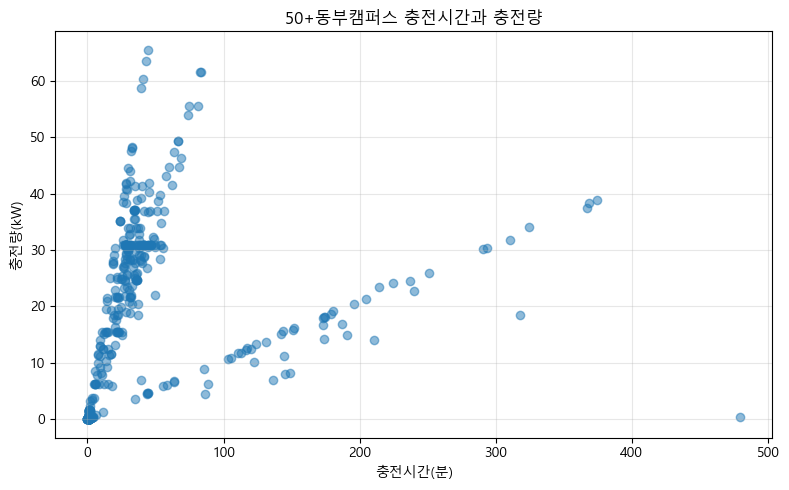

In [94]:
import matplotlib.pyplot as plt

name = "50+동부캠퍼스"

station_data = df_model[
    df_model["충전소명"].astype(str).str.strip() == name
].copy()

print("데이터 개수:", len(station_data))

plt.figure(figsize=(8, 5))
plt.scatter(
    station_data["충전시간_분"],
    station_data["충전량(kW)"],
    alpha=0.5
)

plt.xlabel("충전시간(분)")
plt.ylabel("충전량(kW)")
plt.title(f"{name} 충전시간과 충전량")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [95]:
name = "50+동부캠퍼스"

outliers = df_model[
    (df_model["충전소명"].astype(str).str.strip() == name) &
    (df_model["충전량(kW)"] <= 20) &
    (df_model["충전시간_분"] >= 300)
]

display(
    outliers[
        ["충전소명", "충전시작시간", "충전종료시간",
         "충전시간_분", "충전량(kW)"]
    ]
)

print("해당 데이터 인덱스:", outliers.index.tolist())

,충전소명,충전시작시간,충전종료시간,충전시간_분,충전량(kW)
139362,50+동부캠퍼스,2025-05-31 13:06:23,2025-05-31 18:24:35,318.200000,18.45
160337,50+동부캠퍼스,2025-04-18 10:58:26,2025-04-18 18:57:48,479.366667,0.38


해당 데이터 인덱스: [139362, 160337]


In [96]:

# 앵봉산가족캠핑장 이상치 삭제
df_model = df_model.drop(index=132727, errors="ignore")

# 남산청사 이상치 삭제
df_model = df_model.drop(index=136756, errors="ignore")

# 50+동부캠퍼스 이상치 2개 제거
df_model = df_model.drop(index=[139362, 160337], errors="ignore")

# 불암산공영주차장 삭제
df_model = df_model.drop(index=[47874], errors="ignore")

# 여의서로 노상공영주차장(가로등) 삭제
df_model = df_model.drop(index=[20577], errors="ignore")

# 노원구청 이상치 2개 제거
df_model = df_model.drop(index=[91016, 90663], errors="ignore")

## 한마음공영주차장 제거
df_model = df_model.drop(index=[211049], errors="ignore")

#  어린이대공원 구의문 주차장 복합충전소 이상치 2개 삭제
df_model = df_model.drop(index=[90474, 157271], errors="ignore")

# 교통공원길 충전시간 이상치 후보 제거
df_model = df_model.drop(index=[138608], errors="ignore")

# 월계복지문화센터 이상치 데이터 제거
df_model = df_model.drop(index=[30478], errors="ignore")

# 고척스카이돔 이상치 데이터 제거
df_model = df_model.drop(index=[143415], errors="ignore")

# 마포유수지 공영주차장 이상치 데이터 제거
df_model = df_model.drop(index=[193769], errors="ignore")



In [97]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

# 충전소별 선형회귀 재평가
for name, data in df_model.groupby("충전소명"):

    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    # 데이터가 너무 적거나 충전시간이 모두 같으면 제외
    if len(data) < 10 or data["충전시간_분"].nunique() < 2:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "충전소명": name,
        "데이터 수": len(data),
        "실제 평균 충전량": y_test.mean(),
        "예측 평균 충전량": y_pred.mean(),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

# R²가 0보다 작은 충전소만 추출
negative_r2 = results_df[results_df["R2"] < 0].sort_values("R2")

display(negative_r2.round(4))



,충전소명,데이터 개수,MAE,RMSE,R2
190,앵봉산가족캠핑장,102,25.7376,95.6927,-32.8042
189,남산청사,1203,2.6424,14.2736,-7.1110
188,한마음공영주차장,933,11.1060,32.2181,-2.6625
187,마포유수지 공영주차장,1235,10.5337,29.5237,-2.4686
186,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.0161,30.1786,-2.4640
185,여의서로 노상공영주차장(가로등),1663,5.9485,21.6726,-1.9031
184,불암산공영주차장,196,10.7611,20.6133,-1.2676
183,노원구청,1046,10.4137,16.8678,-0.3861
182,어린이대공원 구의문 주차장 복합충전소,4065,11.8162,15.8723,-0.0927
181,교통공원길 공영주차장 전기차 충전소,1520,13.0054,19.2459,-0.0211


In [98]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

# 충전소별 모델 재학습
for name, data in df_model.groupby("충전소명"):

    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    if len(data) < 10 or data["충전시간_분"].nunique() < 2:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "충전소명": name,
        "데이터 수": len(data),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

# 결과 갱신
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("R2").reset_index(drop=True)

# R²가 음수인 충전소만 출력
negative_r2 = results_df[results_df["R2"] > 0]

display(negative_r2.round(4))

,충전소명,데이터 수,MAE,RMSE,R2
2,가산 공영주차장,420,6.8220,8.3047,0.0091
3,목동공영주차장,3260,12.8778,15.5745,0.0463
4,동작구청,2826,4.7018,5.7387,0.0516
5,송월동차고지,2935,12.1664,15.0812,0.0645
6,수서역 공영주차장 복합충전소,3924,11.3613,14.0996,0.0754
...,...,...,...,...,...
186,로봇과학관,87,0.9418,1.5183,0.9812
187,으뜸공원 공영주차장 전기차 충전소,439,1.4564,2.0969,0.9841
188,봉화산역 공영주차장 전기차 충전소,756,1.5716,2.1419,0.9867
189,미아동 도봉세무서 앞 전기차 충전소,518,1.1629,1.8785,0.9912


In [99]:
# 처음에 R²가 음수였던 13개 충전소
target_stations = [
    "앵봉산가족캠핑장",
    "남산청사",
    "한마음공영주차장",
    "마포유수지 공영주차장",
    "국립한글박물관 지하주차장(주차장 임시폐쇄)",
    "여의서로 노상공영주차장(가로등)",
    "불암산공영주차장",
    "노원구청",
    "어린이대공원 구의문 주차장 복합충전소",
    "교통공원길 공영주차장 전기차 충전소",
    "50+동부캠퍼스",
    "월계복지문화센터",
    "고척스카이돔"
]

# 최신 df_model로 해당 충전소들만 재평가
comparison_results = []

for name in target_stations:
    data = df_model[
        df_model["충전소명"].astype(str).str.strip() == name
    ][["충전시간_분", "충전량(kW)"]].dropna()

    if len(data) < 10 or data["충전시간_분"].nunique() < 2:
        print(f"데이터 부족 또는 충전시간 변동 없음: {name}")
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    comparison_results.append({
        "충전소명": name,
        "데이터 수": len(data),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,충전소명,데이터 수,MAE,RMSE,R2
0,앵봉산가족캠핑장,101,4.4693,5.8624,0.8673
1,남산청사,1202,1.7222,2.3300,0.7789
2,한마음공영주차장,932,8.8424,11.2735,0.5745
3,마포유수지 공영주차장,1234,8.7918,11.1287,0.5266
4,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.0161,30.1786,-2.4640
5,여의서로 노상공영주차장(가로등),1662,4.7477,6.4601,0.7562
6,불암산공영주차장,195,8.0501,9.6667,0.5071
7,노원구청,1044,8.8668,11.6598,0.4232
8,어린이대공원 구의문 주차장 복합충전소,4063,11.1306,13.7638,0.1414
9,교통공원길 공영주차장 전기차 충전소,1519,12.6783,16.0407,0.3347


In [100]:
print("df_model 전체 데이터:", len(df_model), "개")

df_model 전체 데이터: 215515 개


In [101]:
print("충전소 개수:", df_model["충전소명"].nunique())

충전소 개수: 213


분석 데이터 수: 215515

충전량 기초 통계
count    215515.00
mean         21.54
std          14.91
min           0.00
1%            0.00
5%            0.30
10%           2.18
25%           9.55
50%          19.79
75%          30.96
90%          42.41
95%          48.15
99%          60.59
max         114.61
Name: 충전량(kW), dtype: float64


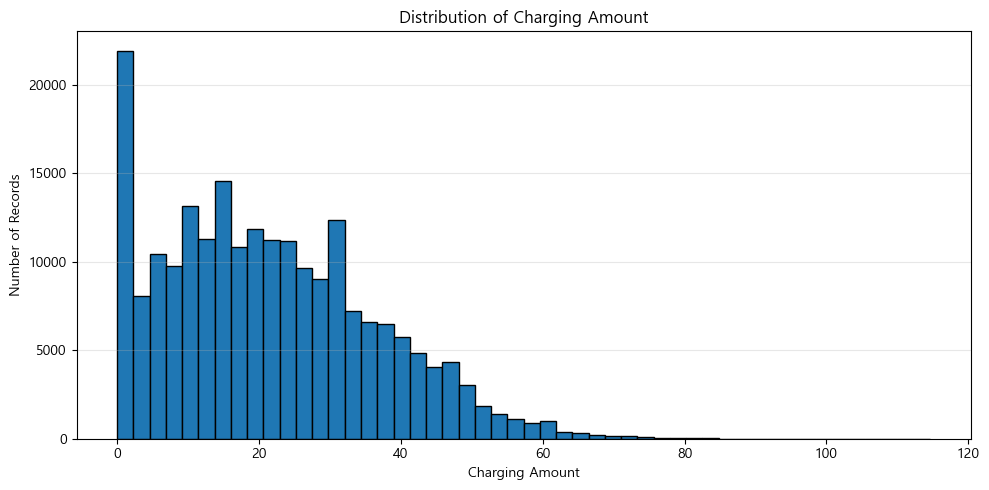

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 현재 이상치 제거가 반영된 데이터 사용
amount = df_model["충전량(kW)"].dropna()

print("분석 데이터 수:", len(amount))
print("\n충전량 기초 통계")
print(amount.describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).round(2))

# 충전량 분포 그래프
plt.figure(figsize=(10, 5))
plt.hist(amount, bins=50, edgecolor="black")
plt.xlabel("Charging Amount")
plt.ylabel("Number of Records")
plt.title("Distribution of Charging Amount")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

R² 양수인 충전소 수: 189

예측 데이터 개수: 42892
최종 예측 충전소 수: 189

[예측 충전량 통계]
count    42892.00
mean        21.60
std         11.36
min         -1.72
1%           0.80
5%           4.01
25%         13.54
50%         21.55
75%         28.31
95%         40.88
99%         53.39
max         98.90
Name: 예측 충전량, dtype: float64

[사분위수]
1사분위수(Q1, 25%): 13.54
3사분위수(Q3, 75%): 28.31
사분위 범위(IQR): 14.77


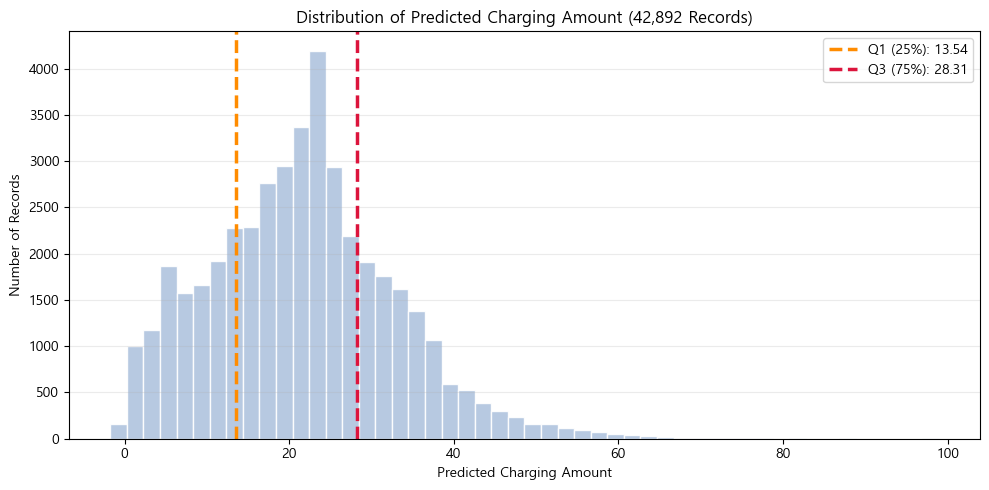

엑셀 파일 저장 완료!
저장 위치: C:\test\06_코드및노트북\충전소별_예측충전량.xlsx


In [112]:

# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 한글 폰트 설정 (Windows)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# R²가 양수인 충전소만 선택
valid_stations = set(
    results_df.loc[results_df["R2"] > 0, "충전소명"]
)

print("R² 양수인 충전소 수:", len(valid_stations))

# 예측 결과 저장 리스트
predictions = []

# R²가 양수인 충전소만 모델 학습 및 예측
for name, data in df_model.groupby("충전소명"):

    # R²가 양수가 아닌 충전소는 제외
    if name not in valid_stations:
        continue

    # 필요한 열만 선택하고 결측값 제거
    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    # 데이터가 10개 미만이거나 충전시간이 모두 같으면 제외
    if len(data) < 10 or data["충전시간_분"].nunique() < 2:
        continue

    # 입력 데이터와 정답 데이터
    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    # 학습 데이터와 테스트 데이터 분리
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    # 선형회귀 모델 학습
    model = LinearRegression()
    model.fit(X_train, y_train)

    # 테스트 데이터 예측
    y_pred = model.predict(X_test)

    # 예측 결과 저장
    for value in y_pred:
        predictions.append({
            "충전소명": name,
            "예측 충전량": value
        })

# 예측 결과를 데이터프레임으로 변환
predictions_df = pd.DataFrame(predictions)

# 예측 결과 확인
if predictions_df.empty:
    print("예측 결과가 없습니다. 데이터를 확인해주세요.")

else:
    # 예측 데이터 개수 및 충전소 수
    print("\n예측 데이터 개수:", len(predictions_df))
    print("최종 예측 충전소 수:", predictions_df["충전소명"].nunique())

    # 예측 충전량
    pred = predictions_df["예측 충전량"]

    # 예측값 통계 확인
    print("\n[예측 충전량 통계]")
    print(
        pred.describe(
            percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
        ).round(2)
    )

    # 1사분위수(Q1), 3사분위수(Q3) 계산
    q1 = pred.quantile(0.25)
    q3 = pred.quantile(0.75)

    print("\n[사분위수]")
    print(f"1사분위수(Q1, 25%): {q1:.2f}")
    print(f"3사분위수(Q3, 75%): {q3:.2f}")
    print(f"사분위 범위(IQR): {q3 - q1:.2f}")

    # 예측 충전량 분포 히스토그램
    plt.figure(figsize=(10, 5))

    plt.hist(
        pred,
        bins=50,
        color="lightsteelblue",
        edgecolor="white",
        alpha=0.9
    )

    # 1사분위수 기준선
    plt.axvline(
        q1,
        color="darkorange",
        linestyle="--",
        linewidth=2.5,
        label=f"Q1 (25%): {q1:.2f}"
    )

    # 3사분위수 기준선
    plt.axvline(
        q3,
        color="crimson",
        linestyle="--",
        linewidth=2.5,
        label=f"Q3 (75%): {q3:.2f}"
    )

    # 그래프 제목 및 축 설정
    plt.xlabel("Predicted Charging Amount")
    plt.ylabel("Number of Records")
    plt.title(
        f"Distribution of Predicted Charging Amount "
        f"({len(pred):,} Records)"
    )

    plt.legend()
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    # %% 예측 충전량 엑셀 파일 저장

from pathlib import Path

# 저장할 폴더 경로
save_path = Path(r"C:\test\06_코드및노트북")

# 폴더가 없으면 생성
save_path.mkdir(parents=True, exist_ok=True)

# 엑셀 파일 저장 경로
excel_path = save_path / "충전소별_예측충전량.xlsx"

# 예측 결과 저장
predictions_df.to_excel(
    excel_path,
    index=False,
    engine="openpyxl"
)

print("엑셀 파일 저장 완료!")
print("저장 위치:", excel_path)


In [104]:
# 예측 충전량의 분포 확인
print(predictions_df["예측 충전량"].describe())

# 낮음·높음 기준 계산
low_threshold = predictions_df["예측 충전량"].quantile(0.25)
high_threshold = predictions_df["예측 충전량"].quantile(0.75)

print("낮음 기준:", low_threshold)
print("높음 기준:", high_threshold)

count    42892.000000
mean        21.601832
std         11.359819
min         -1.723389
25%         13.537759
50%         21.549910
75%         28.305201
max         98.902314
Name: 예측 충전량, dtype: float64
낮음 기준: 13.537758922578233
높음 기준: 28.305201166227405


In [105]:
# 음수 예측값을 0으로 보정
predictions_df["예측 충전량_보정"] = (
    predictions_df["예측 충전량"].clip(lower=0)
)

# 보정 후 분포 확인
print(predictions_df["예측 충전량_보정"].describe())

# 보정된 예측값으로 낮음·높음 기준 계산
low_threshold = predictions_df["예측 충전량_보정"].quantile(0.25)
high_threshold = predictions_df["예측 충전량_보정"].quantile(0.75)

print("낮음 기준:", low_threshold)
print("높음 기준:", high_threshold)

count    42892.000000
mean        21.602671
std         11.358202
min          0.000000
25%         13.537759
50%         21.549910
75%         28.305201
max         98.902314
Name: 예측 충전량_보정, dtype: float64
낮음 기준: 13.537758922578233
높음 기준: 28.305201166227405


In [106]:
# 예측에 포함된 충전소 목록 추출
station_list = (
    predictions_df[["충전소명"]]
    .drop_duplicates()
    .sort_values("충전소명")
    .reset_index(drop=True)
)

# 번호 추가
station_list.insert(
    0, "번호", range(1, len(station_list) + 1)
)

print("충전소 개수:", len(station_list))
display(station_list)

충전소 개수: 189


,번호,충전소명
0,1,50+동부캠퍼스
1,2,AI 체육센터
2,3,SK허브수 인근 거주자우선주차장 볼라드형 충전소
3,4,가산 공영주차장
4,5,강남구 압구정 나들목 앞 가로등형 충전기
...,...,...
184,185,홍제동 주영빌딩 앞 전기차 충전소(가로등)
185,186,화곡본동주민센터
186,187,화창운수 앞 가로등형 충전소
187,188,훈련원공원 노상공영주차장(가로등)


In [107]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

# 충전소별 모델 재학습
for name, data in df_model.groupby("충전소명"):

    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    if len(data) < 10 or data["충전시간_분"].nunique() < 2:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "충전소명": name,
        "데이터 수": len(data),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

# 결과 갱신
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("R2").reset_index(drop=True)

# R²가 음수인 충전소만 출력
negative_r2 = results_df[results_df["R2"] > 0]

display(negative_r2.round(4))

,충전소명,데이터 수,MAE,RMSE,R2
2,가산 공영주차장,420,6.8220,8.3047,0.0091
3,목동공영주차장,3260,12.8778,15.5745,0.0463
4,동작구청,2826,4.7018,5.7387,0.0516
5,송월동차고지,2935,12.1664,15.0812,0.0645
6,수서역 공영주차장 복합충전소,3924,11.3613,14.0996,0.0754
...,...,...,...,...,...
186,로봇과학관,87,0.9418,1.5183,0.9812
187,으뜸공원 공영주차장 전기차 충전소,439,1.4564,2.0969,0.9841
188,봉화산역 공영주차장 전기차 충전소,756,1.5716,2.1419,0.9867
189,미아동 도봉세무서 앞 전기차 충전소,518,1.1629,1.8785,0.9912


In [108]:
print("충전소 개수:", df_model["충전소명"].nunique())

충전소 개수: 213


In [109]:
print("df_model 전체 충전소:", df_model["충전소명"].nunique())
print("모델 학습에 포함된 충전소:", results_df["충전소명"].nunique())
print("R² 음수인 충전소:", (results_df["R2"] < 0).sum())
print("R² 양수인 충전소:", (results_df["R2"] > 0).sum())

df_model 전체 충전소: 213
모델 학습에 포함된 충전소: 191
R² 음수인 충전소: 2
R² 양수인 충전소: 189


In [110]:
# R²가 음수인 충전소 목록
negative_r2 = results_df[results_df["R2"] < 0]

display(negative_r2.round(4))

,충전소명,데이터 수,MAE,RMSE,R2
0,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.0161,30.1786,-2.4640
1,고척스카이돔,1340,11.5581,14.4376,-0.0079


In [111]:
# 예측값 분포 분석
pred = predictions_df["예측 충전량"].dropna()

# 10개 구간으로 나눠서 가장 많이 분포한 구간 찾기
counts, edges = np.histogram(pred, bins=10)

most_common = counts.argmax()

print("예측값 전체 개수:", len(pred))
print(
    f"가장 많이 분포한 구간: "
    f"{edges[most_common]:.2f} ~ {edges[most_common + 1]:.2f}"
)
print("해당 구간의 예측값 개수:", counts[most_common])
print(f"전체 대비 비율: {counts[most_common] / len(pred) * 100:.2f}%")

# 중앙 50% 범위
q1 = pred.quantile(0.25)
q3 = pred.quantile(0.75)

print(f"중앙 50% 예측 범위: {q1:.2f} ~ {q3:.2f}")

예측값 전체 개수: 42892
가장 많이 분포한 구간: 18.40 ~ 28.46
해당 구간의 예측값 개수: 15639
전체 대비 비율: 36.46%
중앙 50% 예측 범위: 13.54 ~ 28.31


In [121]:

# %% 충전소별 대표 예측 충전량 계산

import pandas as pd
import numpy as np
from pathlib import Path

# 방금 불러온 엑셀 데이터 사용
df = power_df.copy()

results = []

# 충전소별로 예측값 분석
for name, group in df.groupby("충전소명"):

    values = group["예측 충전량"].dropna()

    if len(values) == 0:
        continue

    # 예측값을 10개 구간으로 분할
    counts, edges = np.histogram(values, bins=10)

    # 예측값이 가장 많이 들어간 구간
    idx = counts.argmax()

    lower = edges[idx]
    upper = edges[idx + 1]
    count = counts[idx]

    # 해당 구간의 중앙값을 대표 예측값으로 설정
    representative_value = (lower + upper) / 2

    results.append({
        "충전소명": name,
        "예측값 개수": len(values),
        "최다 분포 구간 하한": lower,
        "최다 분포 구간 상한": upper,
        "구간 내 예측값 개수": count,
        "구간 내 비율(%)": round(count / len(values) * 100, 2),
        "대표 예측값": representative_value
    })

# 결과 정리
result_df = pd.DataFrame(results)

result_df = result_df.sort_values(
    "대표 예측값"
).reset_index(drop=True)

print("분석한 충전소 수:", len(result_df))
display(result_df.head(10))

# 새 엑셀 파일 저장
output_path = Path(
    r"C:\test\06_코드및노트북\충전소별_대표예측충전량.xlsx"
)

result_df.to_excel(output_path, index=False, engine="openpyxl")

print("\n저장 완료:", output_path)


분석한 충전소 수: 189


,충전소명,예측값 개수,최다 분포 구간 하한,최다 분포 구간 상한,구간 내 예측값 개수,구간 내 비율(%),대표 예측값
0,양천구청,340,0.048378,2.080701,94,27.65,1.064539
1,로봇과학관,18,-0.603238,3.238206,8,44.44,1.317484
2,숭인도담공영주차장,3,1.384581,2.638129,2,66.67,2.011355
3,강남주민편익시설(가로등),150,0.111771,4.078042,29,19.33,2.094906
4,남산청사,241,1.181246,3.028444,53,21.99,2.104845
5,하월곡동 거주자우선주차장,16,0.305916,3.955988,5,31.25,2.130952
6,중랑천 환경센터,22,-0.047614,4.766840,8,36.36,2.359613
7,봉화산역 공영주차장 전기차 충전소,152,-0.424726,5.391536,47,30.92,2.483405
8,수락산 근린공원 공영주차장,10,1.056974,4.492340,6,60.00,2.774657
9,사당5동 주민센터 거주자주차장 14번(가로등),343,1.014875,4.595365,64,18.66,2.805120



저장 완료: C:\test\06_코드및노트북\충전소별_대표예측충전량.xlsx


In [122]:
#성능평가


# %% 충전소별 모델 성능 평가 (한 번에 실행)

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. 원본 데이터 확인
# --------------------------------------------------
# 기존 노트북에서 사용한 df_model을 그대로 사용
if "df_model" not in globals():
    raise NameError(
        "df_model이 없습니다. 원본 데이터 전처리 코드를 먼저 실행해 주세요."
    )

required_cols = ["충전소명", "충전시간_분", "충전량(kW)"]

missing_cols = [col for col in required_cols if col not in df_model.columns]
if missing_cols:
    raise KeyError(f"df_model에 필요한 열이 없습니다: {missing_cols}")

# 기존에 사용했던 R² 양수 충전소만 평가
if "results_df" in globals() and {"R2", "충전소명"}.issubset(results_df.columns):
    valid_stations = set(
        results_df.loc[results_df["R2"] > 0, "충전소명"]
    )
else:
    raise NameError(
        "results_df가 없습니다. 기존 충전소별 모델 평가 코드를 먼저 실행해 주세요."
    )

# --------------------------------------------------
# 2. 충전소별 모델 재학습 및 테스트 데이터 예측
# --------------------------------------------------
evaluation_rows = []

for name, data in df_model.groupby("충전소명"):

    if name not in valid_stations:
        continue

    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    if len(data) < 10 or data["충전시간_분"].nunique() < 2:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    for actual, predicted in zip(y_test, y_pred):
        evaluation_rows.append({
            "충전소명": name,
            "실제 충전량": actual,
            "예측 충전량": predicted
        })

evaluation_df = pd.DataFrame(evaluation_rows)

if evaluation_df.empty:
    raise ValueError("평가할 데이터가 없습니다. 원본 데이터와 필터 조건을 확인해 주세요.")

# --------------------------------------------------
# 3. 전체 모델 성능 평가
# --------------------------------------------------
actual = evaluation_df["실제 충전량"]
predicted = evaluation_df["예측 충전량"]

print("=" * 40)
print("전체 모델 성능")
print("=" * 40)
print("평가 데이터 수:", len(evaluation_df))
print("평가 충전소 수:", evaluation_df["충전소명"].nunique())
print(f"MAE  : {mean_absolute_error(actual, predicted):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(actual, predicted)):.4f}")
print(f"R²   : {r2_score(actual, predicted):.4f}")

# --------------------------------------------------
# 4. 충전소별 모델 성능 평가
# --------------------------------------------------
station_metrics = []

for name, group in evaluation_df.groupby("충전소명"):

    actual = group["실제 충전량"]
    predicted = group["예측 충전량"]

    station_metrics.append({
        "충전소명": name,
        "평가 데이터 수": len(group),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": (
            r2_score(actual, predicted)
            if len(group) >= 2 and actual.nunique() >= 2
            else np.nan
        )
    })

station_metrics_df = pd.DataFrame(station_metrics)
station_metrics_df = station_metrics_df.sort_values("MAE")

display(station_metrics_df)

# --------------------------------------------------
# 5. 결과 엑셀 저장
# --------------------------------------------------
output_path = Path(
    r"C:\test\06_코드및노트북\충전소별_모델성능평가.xlsx"
)

station_metrics_df.to_excel(output_path, index=False)

print("\n성능 평가 결과 저장 완료!")
print(output_path)


전체 모델 성능
평가 데이터 수: 42892
평가 충전소 수: 189
MAE  : 6.8284
RMSE : 9.4754
R²   : 0.5949


,충전소명,평가 데이터 수,MAE,RMSE,R2
84,사당종합체육관,40,0.421422,0.543663,0.992709
49,로봇과학관,18,0.941812,1.518333,0.981174
67,미아동 도봉세무서 앞 전기차 충전소,104,1.162947,1.878473,0.991163
112,숭인도담공영주차장,3,1.370020,2.118566,0.752237
140,으뜸공원 공영주차장 전기차 충전소,88,1.456386,2.096946,0.984108
...,...,...,...,...,...
103,송월동차고지,587,12.166415,15.081155,0.064478
139,위례성길 공영주차장 전기차 충전소,268,12.331547,15.254595,0.378777
17,교통공원길 공영주차장 전기차 충전소,304,12.678338,16.040681,0.334730
61,목동공영주차장,652,12.877826,15.574540,0.046303



성능 평가 결과 저장 완료!
C:\test\06_코드및노트북\충전소별_모델성능평가.xlsx


In [128]:

from pathlib import Path
import pandas as pd

# ==========================================
# 1. 파일 경로 설정
# ==========================================
folder = Path(r"C:\test\06_코드및노트북")

input_path = folder / "충전소별_대표예측충전량.xlsx"

# 기존 파일을 보존하고 새 파일로 저장
output_path = folder / "충전소별_대표예측충전량_5등급분류.xlsx"


# ==========================================
# 2. 대표 예측값 파일 불러오기
# ==========================================
df = pd.read_excel(input_path)

print("파일 열 이름:", df.columns.tolist())

# 대표 예측값 열 확인
if "대표 예측값" not in df.columns:
    raise ValueError(
        "'대표 예측값' 열이 없어. 실제 열 이름을 확인해 줘."
    )

# 대표 예측값을 숫자로 변환
df["대표 예측값"] = pd.to_numeric(
    df["대표 예측값"],
    errors="coerce"
)

# 대표 예측값이 없는 행 제거
df = df.dropna(subset=["대표 예측값"]).copy()


# ==========================================
# 3. 대표 예측값 기준으로 5등급 분류
# ==========================================
values = df["대표 예측값"]

# 20%, 40%, 60%, 80% 지점 계산
boundaries = [
    values.quantile(0.2),
    values.quantile(0.4),
    values.quantile(0.6),
    values.quantile(0.8)
]

# A: 매우 적음
# B: 적음
# C: 중간
# D: 많음
# E: 매우 많음
df["등급"] = pd.cut(
    values,
    bins=[
        float("-inf"),
        boundaries[0],
        boundaries[1],
        boundaries[2],
        boundaries[3],
        float("inf")
    ],
    labels=["A", "B", "C", "D", "E"],
    include_lowest=True
)

# 등급 설명 추가
grade_meaning = {
    "A": "매우 적음",
    "B": "적음",
    "C": "중간",
    "D": "많음",
    "E": "매우 많음"
}

df["등급 설명"] = df["등급"].map(grade_meaning)


# ==========================================
# 4. 등급별 경계값 출력
# ==========================================
print("\n========== 5등급 분류 기준 ==========")

print(f"A등급(매우 적음): {values.min():.4f} ~ {boundaries[0]:.4f}")
print(f"B등급(적음): {boundaries[0]:.4f} 초과 ~ {boundaries[1]:.4f}")
print(f"C등급(중간): {boundaries[1]:.4f} 초과 ~ {boundaries[2]:.4f}")
print(f"D등급(많음): {boundaries[2]:.4f} 초과 ~ {boundaries[3]:.4f}")
print(f"E등급(매우 많음): {boundaries[3]:.4f} 초과 ~ {values.max():.4f}")


# ==========================================
# 5. 등급별 충전소 수 확인
# ==========================================
print("\n========== 등급별 충전소 수 ==========")

grade_counts = (
    df.groupby("등급", observed=False)
    .size()
    .reindex(["A", "B", "C", "D", "E"], fill_value=0)
)

for grade, count in grade_counts.items():
    print(f"{grade}등급 ({grade_meaning[grade]}): {count}개")

print("\n전체 행 수:", len(df))

if "충전소명" in df.columns:
    print("고유 충전소 수:", df["충전소명"].nunique())


# ==========================================
# 6. 등급별 대표 예측값 요약
# ==========================================
print("\n========== 등급별 예측값 요약 ==========")

grade_summary = (
    df.groupby("등급", observed=False)["대표 예측값"]
    .agg(["count", "min", "median", "max"])
    .rename(columns={
        "count": "데이터 수",
        "min": "최솟값",
        "median": "중앙값",
        "max": "최댓값"
    })
)

display(grade_summary)


# ==========================================
# 7. 등급 순서대로 정렬
# ==========================================
df["등급_순서"] = df["등급"].cat.codes

df = df.sort_values(
    ["등급_순서", "대표 예측값"]
).drop(columns=["등급_순서"]).reset_index(drop=True)


# ==========================================
# 8. 새 엑셀 파일 저장
# ==========================================
try:
    df.to_excel(output_path, index=False)
    print("\n저장 완료!")
    print("파일 위치:", output_path)

except PermissionError:
    backup_path = folder / "충전소별_대표예측충전량_5등급분류_새파일.xlsx"
    df.to_excel(backup_path, index=False)
    print("\n다른 파일명으로 저장했어.")
    print("파일 위치:", backup_path)


# ==========================================
# 9. 결과 확인
# ==========================================
show_cols = [
    col for col in ["충전소명", "대표 예측값", "등급", "등급 설명"]
    if col in df.columns
]

display(df[show_cols].head(20))


파일 열 이름: ['충전소명', '예측값 개수', '최다 분포 구간 하한', '최다 분포 구간 상한', '구간 내 예측값 개수', '구간 내 비율(%)', '대표 예측값']

========== 5등급 분류 기준 ==========
A등급(매우 적음): 1.0645 ~ 7.3199
B등급(적음): 7.3199 초과 ~ 15.8773
C등급(중간): 15.8773 초과 ~ 21.8483
D등급(많음): 21.8483 초과 ~ 26.8744
E등급(매우 많음): 26.8744 초과 ~ 51.2571

========== 등급별 충전소 수 ==========
A등급 (매우 적음): 38개
B등급 (적음): 38개
C등급 (중간): 37개
D등급 (많음): 38개
E등급 (매우 많음): 38개

전체 행 수: 189
고유 충전소 수: 189

========== 등급별 예측값 요약 ==========


,데이터 수,최솟값,중앙값,최댓값
등급,,,,
A,38,1.064539,4.297456,7.141390
B,38,7.438975,10.278471,15.612388
C,37,16.936862,20.048646,21.767554
D,38,21.868512,23.323567,26.694865
E,38,27.143722,32.020831,51.257055



저장 완료!
파일 위치: C:\test\06_코드및노트북\충전소별_대표예측충전량_5등급분류.xlsx


,충전소명,대표 예측값,등급,등급 설명
0,양천구청,1.064539,A,매우 적음
1,로봇과학관,1.317484,A,매우 적음
2,숭인도담공영주차장,2.011355,A,매우 적음
3,강남주민편익시설(가로등),2.094906,A,매우 적음
4,남산청사,2.104845,A,매우 적음
5,하월곡동 거주자우선주차장,2.130952,A,매우 적음
6,중랑천 환경센터,2.359613,A,매우 적음
7,봉화산역 공영주차장 전기차 충전소,2.483405,A,매우 적음
8,수락산 근린공원 공영주차장,2.774657,A,매우 적음
9,사당5동 주민센터 거주자주차장 14번(가로등),2.805120,A,매우 적음
